# Интерпретация sequence2function-моделей на примере lentiMPRA


## Биологический контекст: что измеряет Agarwal lentiMPRA

В lentiMPRA тысячи 200-нуклеотидных регуляторных фрагментов встраиваются в lentiviral reporter-конструкции. Для каждого фрагмента связываются баркоды, затем секвенируются:

- **DNA barcode counts** — сколько конструкций присутствует;
- **RNA barcode counts** — сколько reporter-транскрипта произведено.

Активность элемента приблизительно определяется как:

$activity = \log_2(\text{RNA counts}/\text{DNA counts})$

В совместном Agarwal-наборе один и тот же фрагмент оценивался в трёх контекстах:

- **HepG2** — печёночно-подобная клеточная линия;
- **K562** — лейкозная клеточная линия с эритроидными особенностями;
- **WTC11** — линия индуцированных плюрипотентных клеток.

Это не измерение экспрессии гена в его естественном локусе: reporter находится в случайных местах интеграции, а исходные enhancer–promoter контакты и локальная 3D-хроматиновая среда не сохраняются полностью.

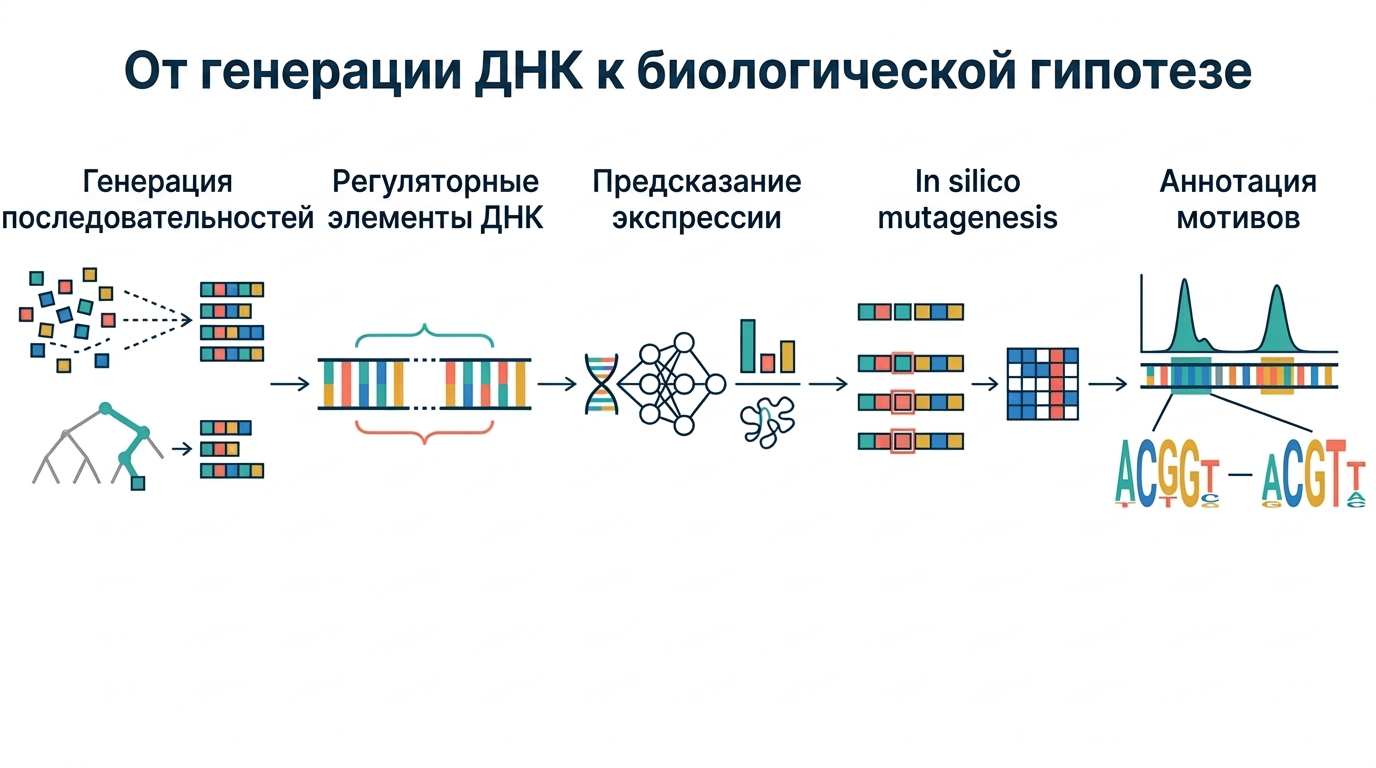


## Что такое sequence2function-модель

Пусть `s` — DNA-последовательность. Модель аппроксимирует функцию:


$f_\theta(s) = (y_{HepG2}, y_{K562}, y_{WTC11})$

Модель предсказатель получает one-hot представление последовательности и извлекает локальные и более длинные комбинации сигналов с помощью свёрточных блоков. В конце общие признаки поступают в голову с тремя регрессионными выходами.

Значение `predicted_*` — это прогноз модели. Значение `queried_*` в файлах генерации — **целевой профиль, который был запрошен у генератора**.

## Attribution: что именно мы хотим объяснить

**Attribution** — это способ сопоставить предсказание модели с входом: каждому основанию или позиции приписывается число, отражающее её влияние на выбранную целевую функцию.

Для модели на основе последовательности важно заранее выбрать, какой эффект мы хотим предсказывать:

- `activity HepG2` — абсолютный прогноз в HepG2;
- `activity K562` — абсолютный прогноз в K562;
- `HepG2 − K562` — клеточный контраст;
- `MinGap HepG2 = HepG2 − max(K562, WTC11)` — активность в таргетной клеточной линии относительно остальных

Одна и та же последовательность может иметь разные карты attribution для разных таргетов.

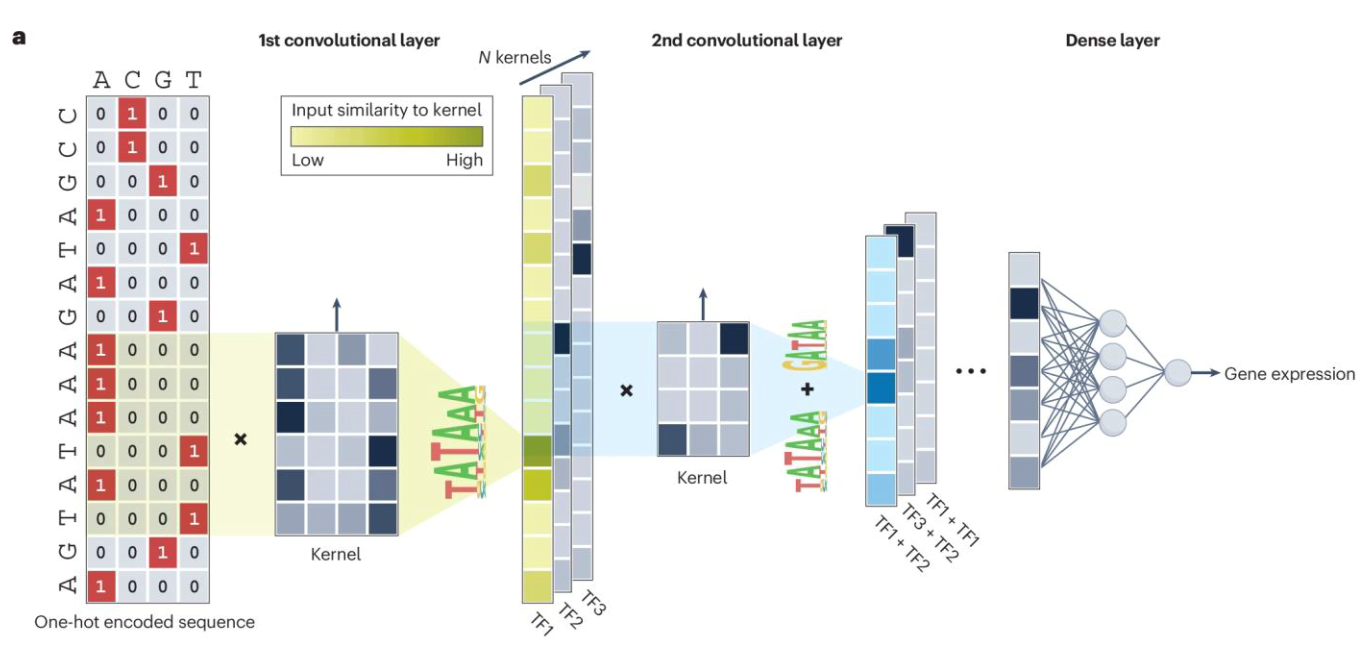


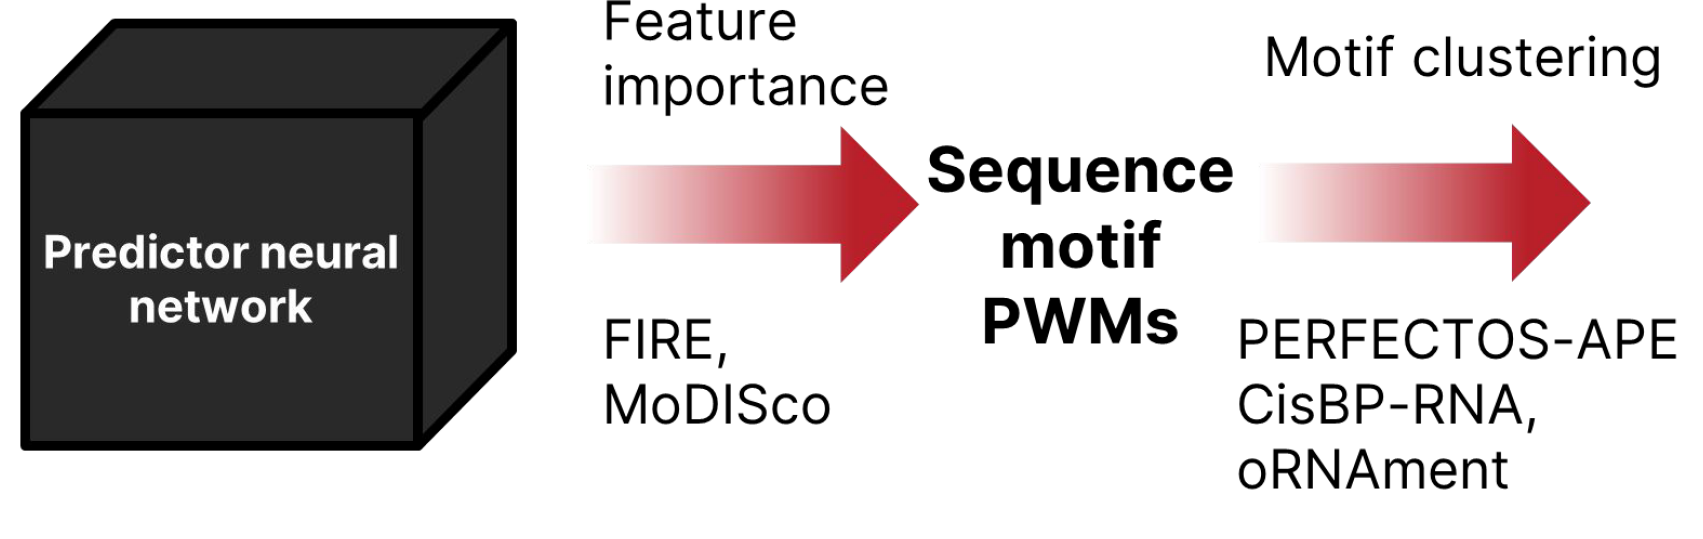


## ISM: In-silico saturation mutagenesis

In-silico saturation mutagenesis (ISM) перебирает все одиночные замены:


$\Delta_{i,b} = f(s_{i\leftarrow b}) - f(s)$

где `i` — позиция, а `b` — один из A/C/G/T.

В Tangermeme для каждой позиции также центрируют эффекты относительно среднего по четырём основаниям. Получается **hypothetical attribution** размерности `4 × L`: что сказала бы модель, если в позиции стояла каждая из букв.

Умножение на исходный one-hot и суммирование по алфавиту даёт **projected attribution** — сигнал для реально присутствующего основания.

**Почему ISM полезен:** он не требует градиентов, непосредственно связан с дискретной мутацией и легко объясняется биологам. **Ограничение:** это локальный анализ одиночных замен; эпистаз и совместные мутации напрямую не измеряются.

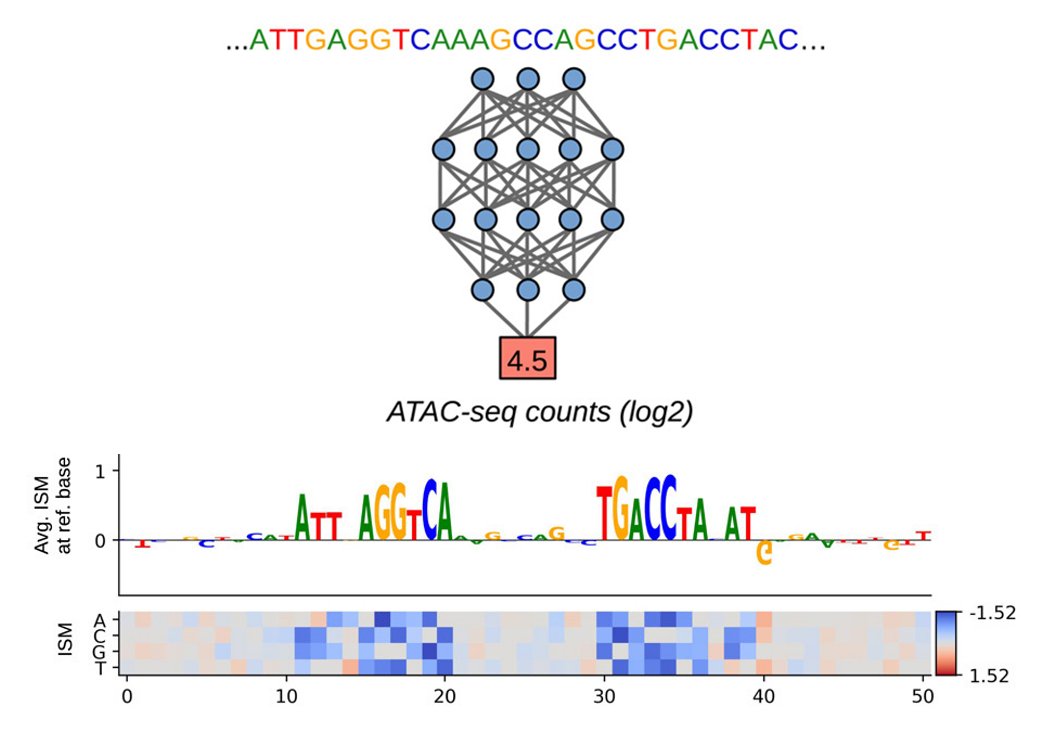


## Техническая оговорка про assay-конструкцию

Checkpoint обучен на входе длины 230 nt:

```text
15 nt constant assay flank + 200 nt insert + 15 nt constant assay flank
```

В ноутбуке модель всегда получает полный 230-nt input, но ISM запускается только для центральных 200 nt. Фланки остаются неизменными и не интерпретируются как найденные биологические мотивы.

In [ ]:
import importlib.util
import os
import sys
from functools import partial
from pathlib import Path

_PROJECT_CANDIDATES = []
for _candidate in [
    Path(os.environ['SIRIUS_ROOT']) if os.environ.get('SIRIUS_ROOT') else None,
    Path.cwd(),
    *Path.cwd().parents,
    Path('/content/sirius2026'),
    Path('/content/sirius_tutorial'),
    Path('/content/drive/MyDrive/sirius2026'),
    Path('/content/drive/MyDrive/sirius_tutorial'),
]:
    if _candidate is not None and _candidate not in _PROJECT_CANDIDATES:
        _PROJECT_CANDIDATES.append(_candidate)
_PROJECT_ROOT = next(
    (candidate for candidate in _PROJECT_CANDIDATES
     if (candidate / 'tutorial_plotting.py').exists()),
    None,
)
if _PROJECT_ROOT is None and importlib.util.find_spec('google.colab') is not None:
    from google.colab import drive
    drive.mount('/content/drive')
    _PROJECT_ROOT = next(
        (candidate for candidate in [
            Path('/content/drive/MyDrive/sirius2026'),
            Path('/content/drive/MyDrive/sirius_tutorial'),
        ] if (candidate / 'tutorial_plotting.py').exists()),
        None,
    )
if _PROJECT_ROOT is None:
    raise FileNotFoundError(
        'Cannot find the cloned Sirius repository. Expected /content/sirius2026 '
        'or a notebook launched from the repository root.'
    )
sys.path.insert(0, str(_PROJECT_ROOT))

!pip install -q -r "{_PROJECT_ROOT / 'requirements.txt'}"

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import clear_output, display

from tangermeme.annotate import read_meme
from tangermeme.saturation_mutagenesis import saturation_mutagenesis
from tangermeme.seqlet import recursive_seqlets
from utils import decode_onehot_tensor, encode_core

if torch.cuda.is_available():
    DEVICE = 'cuda:1' if torch.cuda.device_count() > 1 else 'cuda:0'
else:
    DEVICE = 'cpu'
print('PyTorch:', torch.__version__)
print('Device:', DEVICE)
if DEVICE.startswith('cuda'):
    print('GPU:', torch.cuda.get_device_name(torch.device(DEVICE)))


In [ ]:
DEVICE

In [ ]:
# Пути к данным. Все assets поставляются внутри клона репозитория.
PORTABLE_ROOTS = []
for _candidate in [
    _PROJECT_ROOT,
    Path.cwd(),
    Path('/content/sirius2026'),
    Path('/content/sirius_tutorial'),
    Path('/content/drive/MyDrive/sirius2026'),
    Path('/content/drive/MyDrive/sirius_tutorial'),
]:
    if _candidate is not None and _candidate not in PORTABLE_ROOTS:
        PORTABLE_ROOTS.append(_candidate)

PORTABLE_ROOT = next(
    (candidate for candidate in PORTABLE_ROOTS
     if (candidate / 'models').exists()
     and (candidate / 'frameworks').exists()
     and (candidate / 'motifs').exists()),
    None,
)
if PORTABLE_ROOT is None:
    raise FileNotFoundError(
        'Tutorial assets are missing from the cloned repository. Expected '
        'models/, frameworks/, and motifs/ under the project root.'
    )

FRAMEWORK_DIR = PORTABLE_ROOT / 'frameworks'
WEIGHTS_PATH = PORTABLE_ROOT / 'models' / 'epoch042-r0.79896.ckpt'
MEME_PATH = PORTABLE_ROOT / 'motifs' / 'H14CORE-CLUSTERED_meme_format.meme'

print('Tutorial assets:', PORTABLE_ROOT)
print('Framework directory:', FRAMEWORK_DIR)
print('Weights:', WEIGHTS_PATH)
print('Motif database:', MEME_PATH)
if not FRAMEWORK_DIR.exists() or not WEIGHTS_PATH.exists() or not MEME_PATH.exists():
    raise FileNotFoundError('Tutorial assets are incomplete in the repository clone.')


In [ ]:
model_source = PORTABLE_ROOT / 'vendor' / 'mpramnist' / 'models' / 'MPRALegNet.py'
if not model_source.exists():
    raise FileNotFoundError(f'Cannot find bundled model architecture: {model_source}')
spec = importlib.util.spec_from_file_location('mpramnist_legnet_source', model_source)
legnet_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(legnet_module)

checkpoint = torch.load(WEIGHTS_PATH, map_location='cpu', weights_only=False)

hparams = checkpoint['hyper_parameters']
CELL_TYPES = list(hparams['celltypes'])
model_config = dict(hparams['model_config'])
model_config.pop('left_flank', None)
model_config.pop('right_flank', None)
net = legnet_module.HumanLegNet(in_ch=4, output_dim=len(CELL_TYPES), **model_config)
net.load_state_dict({
    key[len('model.'):]: value
    for key, value in checkpoint['state_dict'].items()
    if key.startswith('model.')
})
net = net.to(DEVICE).eval()

state = checkpoint['state_dict']
ASSAY_LEFT = decode_onehot_tensor(state['left_flank']) if 'left_flank' in state else 'AGGACCGGATCAACT'
ASSAY_RIGHT = decode_onehot_tensor(state['right_flank']) if 'right_flank' in state else 'CATTGCGTGAACCGA'

print('Cell types:', CELL_TYPES)
print('Architecture:', model_config)
print('Model source:', model_source)
print('Assay flanks:', ASSAY_LEFT, ASSAY_RIGHT)
print('Checkpoint epoch:', checkpoint.get('epoch'))


In [ ]:
from utils import predict_sequences as _predict_sequences

predict_sequences = partial(
    _predict_sequences,
    net=net,
    left_flank=ASSAY_LEFT,
    right_flank=ASSAY_RIGHT,
    device=DEVICE,
)

smoke_file = sorted(FRAMEWORK_DIR.glob('*.tsv'))[0]
smoke_seq = pd.read_csv(smoke_file, sep='\t', nrows=1).loc[0, 'sequence']
print('Smoke prediction:', dict(zip(CELL_TYPES, np.round(predict_sequences([smoke_seq])[0], 3))))


## Загружаем готовые дизайны и выбираем контрастные примеры

В каждом TSV находятся 1024 последовательности. Для лекции используем два заранее выбранных примера:

- `mdlm_gamma0.tsv`, строка 862 — сильный HepG2-specific прогноз;
- `permutator_gamma0.tsv`, строка 393 — сильный K562-specific прогноз.

Это не утверждение, что такие последовательности уже экспериментально валидированы. Это хорошие объекты для демонстрации того, как модель формирует гипотезу и насколько эта гипотеза объяснима.

In [ ]:
framework_files = sorted(FRAMEWORK_DIR.glob('*.tsv')) if FRAMEWORK_DIR.exists() else []
all_rows = []
for path in framework_files:
    d = pd.read_csv(path, sep='\t')
    pred_cols = [f'predicted_{ct}' for ct in CELL_TYPES]
    query_cols = [f'queried_{ct}' for ct in CELL_TYPES]
    pred = d[pred_cols].to_numpy()
    order = np.argsort(pred, axis=1)[:, ::-1]
    sorted_pred = np.take_along_axis(pred, order, axis=1)
    d['framework'] = path.stem
    d['row'] = np.arange(len(d))
    d['dominant_cell'] = [CELL_TYPES[i] for i in order[:, 0]]
    d['min_gap'] = sorted_pred[:, 0] - sorted_pred[:, 1]
    d['gc_fraction'] = d['sequence'].map(lambda s: (s.count('G') + s.count('C')) / len(s))
    d['prediction_error'] = np.abs(d[pred_cols].to_numpy() - d[query_cols].to_numpy()).mean(axis=1)
    all_rows.append(d)
summary_df = pd.concat(all_rows, ignore_index=True) if all_rows else pd.DataFrame()
print('Loaded files:', [p.name for p in framework_files])
print('Total sequences:', len(summary_df))
if len(summary_df):
    display(summary_df.groupby(['framework', 'dominant_cell']).size().unstack(fill_value=0))

In [ ]:
EXAMPLES = {
    'HepG2-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 862, 'HepG2'),
    'K562-specific / permutator gamma0': ('permutator_gamma0.tsv', 393, 'K562'),
    'K562-specific / MDLM gamma1': ('mdlm_gamma1.tsv', 459, 'K562'),
    'WTC11-specific / MDLM gamma0': ('mdlm_gamma0.tsv', 367, 'WTC11'),
    'K562-specific / MDLM gamma0 row 649': ('mdlm_gamma0.tsv', 649, 'K562'),
}

from utils import load_example as _load_example
load_example = partial(
    _load_example,
    examples=EXAMPLES,
    framework_dir=FRAMEWORK_DIR,
)

example_records = [load_example(label) for label in EXAMPLES]
example_table = pd.DataFrame(example_records)
cols = ['example', 'source_file', 'source_row', 'target']
for ct in CELL_TYPES:
    cols += [f'queried_{ct}', f'predicted_{ct}']
display(example_table[cols].round(3))


## Fitness-функции для attribution

Внутри модели три выхода. Чтобы получить одну карту ISM, выбираем скалярную fitness-функцию. Это важный ML-момент: attribution относится не просто к последовательности, а к паре **(последовательность, target function)**.

In [ ]:
FITNESS_NAMES = [
    'activity HepG2', 'activity K562', 'activity WTC11',
    'HepG2 - K562', 'K562 - HepG2',
    'MinGap HepG2', 'MinGap K562', 'MinGap WTC11',
]

from utils import fitness_from_predictions as _fitness_from_predictions
fitness_from_predictions = partial(
    _fitness_from_predictions,
    cell_types=CELL_TYPES,
)

class FitnessHead(nn.Module):
    def __init__(self, name):
        super().__init__()
        self.name = name

    def forward(self, x):
        x = x.float()
        y = (net(x) + net(x.flip((1, 2)))) / 2
        indices = {cell_type: index for index, cell_type in enumerate(CELL_TYPES)}
        if self.name.startswith('activity '):
            index = indices[self.name.split()[-1]]
            return y[:, index:index + 1]
        if self.name == 'HepG2 - K562':
            return (y[:, indices['HepG2']] - y[:, indices['K562']]).unsqueeze(1)
        if self.name == 'K562 - HepG2':
            return (y[:, indices['K562']] - y[:, indices['HepG2']]).unsqueeze(1)
        target_index = indices[self.name.split()[-1]]
        other = torch.cat(
            [y[:, :target_index], y[:, target_index + 1:]],
            dim=1,
        ).max(dim=1).values
        return (y[:, target_index] - other).unsqueeze(1)


## Запускаем ISM только на центральной вставке

Tangermeme вернёт hypothetical attribution для всех четырёх оснований в каждой из 200 позиций. Один запуск для одной последовательности и одного fitness — это примерно `200 × 4` однонуклеотидных вариантов, каждый из которых проходит через предсказатель.

In [ ]:
from utils import run_ism as _run_ism

ISM_CACHE = {}
run_ism = partial(
    _run_ism,
    net=net,
    device=DEVICE,
    fitness_head_cls=FitnessHead,
    left_flank=ASSAY_LEFT,
    right_flank=ASSAY_RIGHT,
    saturation_mutagenesis_fn=saturation_mutagenesis,
    recursive_seqlets_fn=recursive_seqlets,
    cache=ISM_CACHE,
)
print('ISM function ready. First interactive run may take a few seconds on GPU.')


In [ ]:
# Motif database: use the clustered HOCOMOCO v14 MEME file when available (648 representatives).
motif_db = read_meme(str(MEME_PATH))
motif_source = str(MEME_PATH)

print('Motif source:', motif_source)
print('Motifs:', len(motif_db))

In [ ]:
from sirius_annotation import DEFAULT_MOTIF_FUNCTIONS, MotifAnnotator
from tutorial_plotting import motif_table_html, plot_ism_panels

MOTIF_FUNCTIONS = DEFAULT_MOTIF_FUNCTIONS
ANNOTATOR = MotifAnnotator(
    motif_db,
    repo_root=PORTABLE_ROOT,
    encode_core=encode_core,
)
IN_COLAB = ANNOTATOR.in_colab
MACROAPE_MODE = ANNOTATOR.macroape_mode
PRECOMPUTED_CACHE = ANNOTATOR.precomputed_cache


def show_example(example_label, fitness_name):
    rec = load_example(example_label)
    result = run_ism(rec['sequence'], fitness_name)
    pred = predict_sequences([rec['sequence']])[0]
    score = fitness_from_predictions(pred[None], fitness_name)[0]
    print(example_label)
    print('model predictions:', dict(zip(CELL_TYPES, np.round(pred, 3))))
    print(f'{fitness_name}: {score:.3f}')
    annotated = ANNOTATOR.annotate(
        result['attr'], result['seqlets'],
        sequence=rec['sequence'], fitness_name=fitness_name,
    )
    plot_ism_panels(
        result['attr'], result['observed_attr'], result['projected'],
        annotated, fitness_name,
    )
    if len(annotated):
        print(rec['sequence'])
        motif_table_html(result, annotated, motif_db, MOTIF_FUNCTIONS)
    else:
        print('No seqlets above the teaching threshold.')
    return result, annotated


## Аннотация

Сначала выберите абсолютную активность. Затем переключите fitness на клеточный контраст. Карта изменится, потому что теперь модель объясняет уже не «почему активность высокая», а «почему активность выше в одной линии, чем в другой».

In [ ]:
import ipywidgets as widgets
example_widget = widgets.Dropdown(options=list(EXAMPLES), value=list(EXAMPLES)[0], description='последовательность:')
fitness_widget = widgets.Dropdown(options=FITNESS_NAMES, value='activity HepG2', description='fitness:')
run_button = widgets.Button(description='Run ISM', button_style='primary')
out = widgets.Output()

def on_run(_):
    with out:
        clear_output(wait=True)
        show_example(example_widget.value, fitness_widget.value)
run_button.on_click(on_run)
display(widgets.HBox([example_widget, fitness_widget, run_button]), out)

## Как читать результат

- **Hypothetical heatmap:** для каждой позиции виден эффект каждой возможной буквы.
- **Projected track:** оставляет только букву, которая реально находится в последовательности.
- **Seqlet:** локальный участок, где сигнал attribution статистически концентрирован.
- **Reference motif:** наиболее похожий PWM из базы; это гипотеза о возможном TF-сигнале.
- **Проверка fitness:** наиболее полезная интерактивная операция — мысленно или программно разрушить сильный участок и проверить, падает ли выбранный score.

Если motif match выглядит убедительно, это всё ещё означает «модель использует паттерн, похожий на этот motif», а не «данный TF доказан экспериментально».
